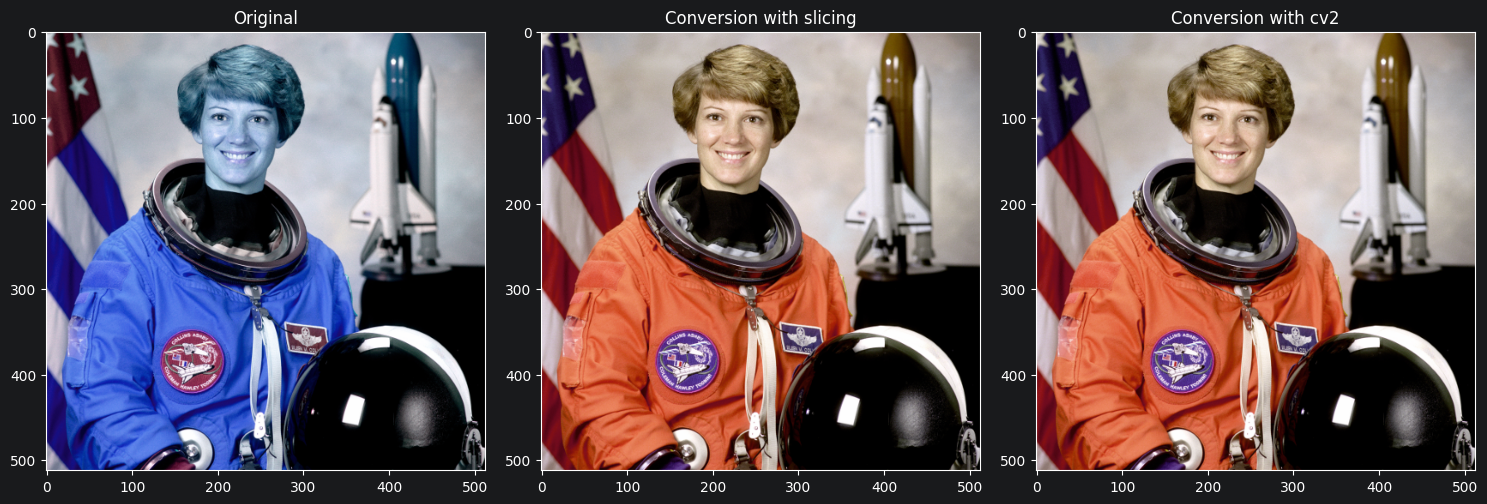

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

astronaut = cv2.imread("astronaut.png")
badge = cv2.imread("badge.png")

rgb_cv2 = cv2.cvtColor(astronaut.copy(), cv2.COLOR_BGR2RGB)
rgb_slicing = astronaut.copy()[:, :, ::-1]

fig, (plt_1, plt_2, plt_3) = plt.subplots(1, 3, figsize=(15, 5))

plt_1.imshow(astronaut)
plt_1.set_title("Original")

plt_2.imshow(rgb_slicing)
plt_2.set_title("Conversion with slicing")

plt_3.imshow(rgb_cv2)
plt_3.set_title("Conversion with cv2")

plt.tight_layout()
plt.show()

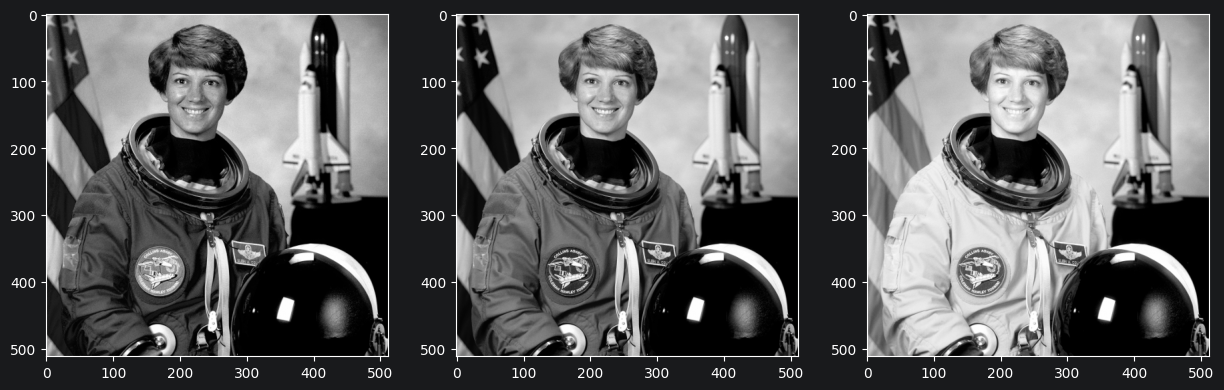

In [2]:
blue_channel = astronaut[:, :, 0]
green_channel = astronaut[:, :, 1]
red_channel = astronaut[:, :, 2]

fig, (plt_1, plt_2, plt_3) = plt.subplots(1, 3, figsize=(15, 5))

plt_1.imshow(blue_channel, cmap="gray", vmin=0, vmax=255)
plt_2.imshow(green_channel, cmap="gray", vmin=0, vmax=255)
plt_3.imshow(red_channel, cmap="gray", vmin=0, vmax=255)


The red channel appears to be the brightest on the orange suit because orange is closest to red and so in grayscale, it will have the brightest values.

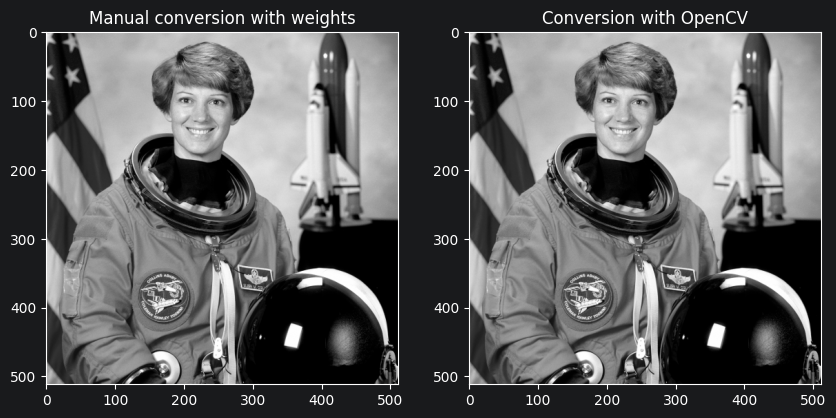

In [3]:
cv_weights = np.array([0.114, 0.587, 0.299])

manual_gray = np.round(astronaut.astype(np.float32) @ cv_weights).astype(np.uint8)
cv_gray = cv2.cvtColor(astronaut, cv2.COLOR_BGR2GRAY)

fig, (plt_1, plt_2) = plt.subplots(1, 2, figsize=(10, 5))

plt_1.imshow(manual_gray, cmap="gray", vmin=0, vmax=255)
plt_1.set_title("Manual conversion with weights")
plt_2.imshow(cv_gray, cmap="gray", vmin=0, vmax=255)
plt_2.set_title("Conversion with OpenCV")

max_diff = np.max(np.abs(manual_gray.astype(np.float32) - cv_gray.astype(np.float32)))
assert max_diff <= 1.0

plt.show()

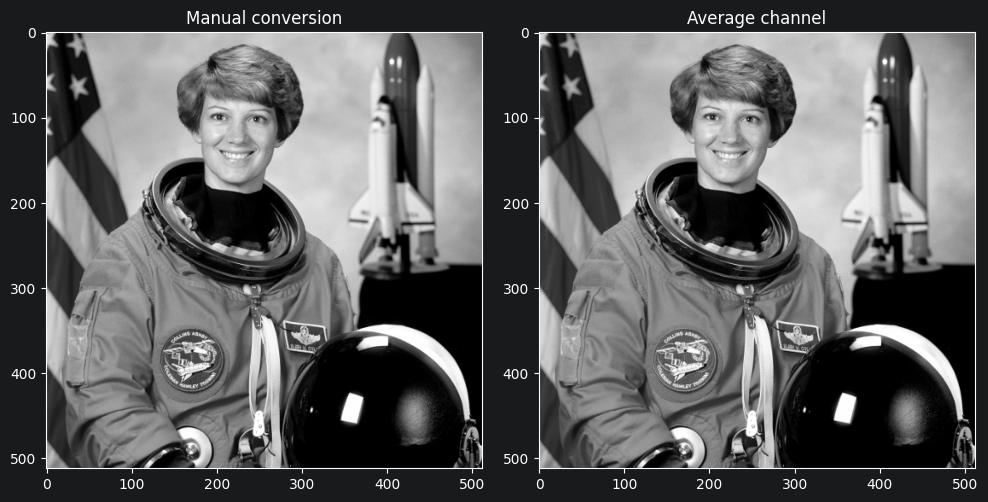

Pixel location (row, col): (489, 152)
Pixel value from Plain Channel Average: 122.66666666666667
Pixel value from Rec.601 weight: 151.0
BGR channel values at original image: [ 35 165 168]


In [4]:
# Compute the channel average without overflow, i.e. bump the dtype to int64
plain_channel_average = (red_channel.astype(np.float64) + green_channel.astype(
        np.float64) + blue_channel.astype(np.float64)) / 3

rec_601_average = manual_gray.astype(np.float64)

fig, (plt_1, plt_2) = plt.subplots(1, 2, figsize=(10, 5))

plt_1.imshow(rec_601_average, cmap="gray", vmin=0, vmax=255)
plt_1.set_title("Manual conversion")
plt_2.imshow(plain_channel_average, cmap="gray", vmin=0, vmax=255)
plt_2.set_title("Average channel")

plt.tight_layout()
plt.show()

### Difference map
difference = np.abs(rec_601_average - plain_channel_average)
max_difference_idx = np.argmax(difference)
diff_row, diff_col = np.unravel_index(max_difference_idx, difference.shape)

print(f"Pixel location (row, col): ({diff_row}, {diff_col})")
print(f"Pixel value from Plain Channel Average: {plain_channel_average[diff_row, diff_col]}")
print(f"Pixel value from Rec.601 weight: {rec_601_average[diff_row, diff_col]}")

original_pixel = astronaut[diff_row, diff_col]
print(f"BGR channel values at original image: {original_pixel}")

The difference between the pixel value from the Plain channel average vs the Rec.601 is quite large because the plain average gives equal importance to both B, G, and R channels, whilst the `Rec.601` gives different importance

Badge shape: (96, 96, 4)


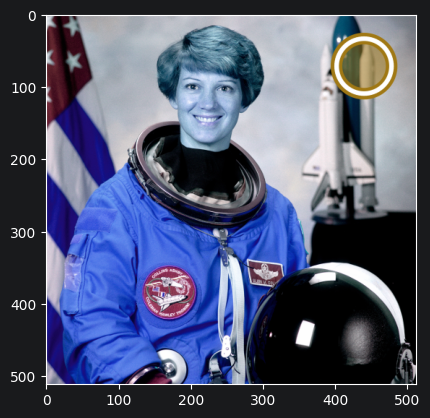

In [5]:
badge = cv2.imread("badge.png", cv2.IMREAD_UNCHANGED)
badge_width, badge_height, _ = badge.shape
print(f"Badge shape: {badge.shape}")

badge_fg = badge[:, :, :3]
badge_alpha = badge[:, :, 3:4] / 255

transpose_region = astronaut[24:24 + badge_height, 392:392 + badge_width]

transpose_out = badge_alpha * badge_fg + (1 - badge_alpha) * transpose_region
transpose_out = transpose_out.astype(np.uint8)

transposed_img = astronaut.copy()
transposed_img[24:24 + badge_height, 392:392 + badge_width] = transpose_out

plt.imshow(transposed_img, cmap="gray", vmin=0, vmax=255)


Text(0.5, 1.0, 'Composition with naive')

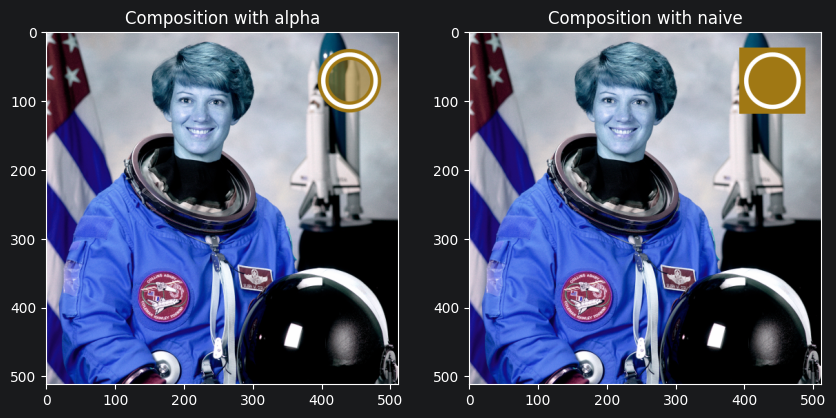

In [6]:
naive_image = astronaut.copy()
naive_image[24:24 + badge_height, 392:392 + badge_width] = badge[:, :, :3]

fig, (plt_1, plt_2) = plt.subplots(1, 2, figsize=(10, 5))

plt_1.imshow(transposed_img, cmap="gray", vmin=0, vmax=255)
plt_1.set_title("Composition with alpha")

plt_2.imshow(naive_image, cmap="gray", vmin=0, vmax=255)
plt_2.set_title("Composition with naive")

Without the alpha channel, all transparent pixels default to opacity 1, which gives it a colour. this means compositing the badge with the astronaut gives us a filled image, as shown in the comparison above